In [1]:
import matplotlib.pyplot as plt

import sys
sys.path.append('../../')

# Import methods
import NLS_Cubic.Methods as NLS
from QGP.Soliton_Gen import *
from Utilities import *

import config

i = 1j

In [84]:
L = 20
N = 1_000
k = 0
p = 2
pars = {"p":p}
c = -np.sqrt(2)/2 #-8 # Hay relacion entre el absorbing layer y la velocidad del soliton
w = 0.2
x_0 = -10

w_stand_theo, x_stand = soliton(c, k, w=w, p=p, soliton_type="bright", L=L, N=N+1, as_func=True)

Creating soliton...
Soliton created


In [85]:
def theo_soliton(x, t, c=c, w=w):
    i = 1j
    output = w_stand_theo(x-x_0-c*t) * np.exp(-i*(c**2/4*t+w*t))
    return output


    np.sqrt(2*w) * sech(np.sqrt(w)*(x - x_0)) * np.exp(-i*(c/2*x))

In [88]:
tf = 40
Nt = 3000 

pars["l_1"] = -0.5
pars["l_2"] = -0.5

l_abs = 5
pars["l_abs"] = L + l_abs

w_stand = NLS.CNFD(L, N, Nt, tf, pars, "absorbing layer")
w_stand.set_w_theo(theo_soliton)
w_stand.solve()

Iteration  1  of  3000 . Error:  1.9032884927252694e-13 . Newton iterations:  5
Iteration  2  of  3000 . Error:  1.9055308997999395e-13 . Newton iterations:  5
Iteration  3  of  3000 . Error:  1.9092220751515674e-13 . Newton iterations:  5
Iteration  4  of  3000 . Error:  1.9142514401074536e-13 . Newton iterations:  5
Iteration  5  of  3000 . Error:  1.9206790226716505e-13 . Newton iterations:  5
Iteration  6  of  3000 . Error:  1.9284431920742064e-13 . Newton iterations:  5
Iteration  7  of  3000 . Error:  1.9378881192617657e-13 . Newton iterations:  5
Iteration  8  of  3000 . Error:  1.9483066855238256e-13 . Newton iterations:  5
Iteration  9  of  3000 . Error:  1.9603801787525144e-13 . Newton iterations:  5
Iteration  10  of  3000 . Error:  1.9737183441598416e-13 . Newton iterations:  5
Iteration  11  of  3000 . Error:  1.9882839877960745e-13 . Newton iterations:  5
Iteration  12  of  3000 . Error:  2.0044845549390485e-13 . Newton iterations:  5
Iteration  13  of  3000 . Error:  2.0

In [75]:
w_stand.w = w_stand.w[:, w_stand.left_border_ind:w_stand.right_border_ind+1]
w_stand.x = w_stand.x_original

MovieWriter ffmpeg unavailable; using Pillow instead.


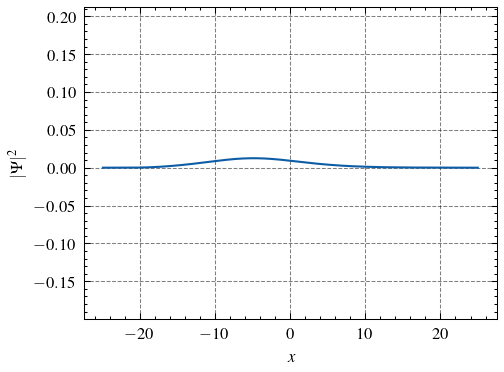

In [89]:
w_stand.animate_solution("test_4.gif", 20)

In [2]:
L = 20
N = 8_000
k = 0

p = 2
pars = {"p":p}

tf = 20
Nt = 2000 

def init_cond(x):
    output = 1/4 * sech(x) #np.exp(-x**2/np.sqrt(2)) #2*sech(x/np.sqrt(2)) + i*sech(x/np.sqrt(2))*np.tanh(x/np.sqrt(2))
    return output

pars["l_1"] = -1e-5
pars["l_2"] = -1e-5

l_abs = 20
pars["l_abs"] = L + l_abs

w_two_sol = NLS.CNFD(L, N, Nt, tf, pars, "absorbing layer")
w_two_sol.set_init_condition(init_cond)
w_two_sol.solve()

Iteration  1  of  2000 . Error:  5.457897748188111e-13 . Newton iterations:  4
Iteration  2  of  2000 . Error:  5.454585271998146e-13 . Newton iterations:  4
Iteration  3  of  2000 . Error:  5.439694725222538e-13 . Newton iterations:  4
Iteration  4  of  2000 . Error:  5.413627654760007e-13 . Newton iterations:  4
Iteration  5  of  2000 . Error:  5.377347729181564e-13 . Newton iterations:  4


KeyboardInterrupt: 

In [ ]:
w_two_sol.w = w_two_sol.w[:, w_two_sol.left_border_ind:w_two_sol.right_border_ind+1]
w_two_sol.x = w_two_sol.x_original

In [ ]:
w_two_sol.animate_solution("sech.gif", 80)

MovieWriter ffmpeg unavailable; using Pillow instead.


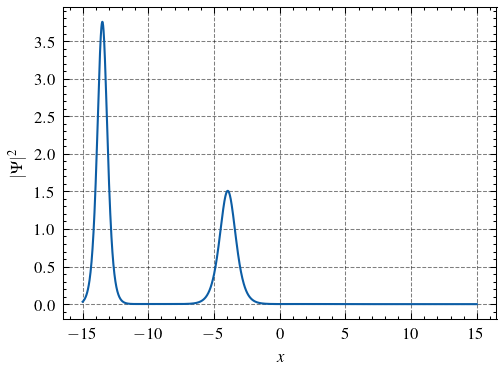

In [64]:
w_two_sol.animate_solution("two_soliton.gif", 20)

In [7]:
L = 20
N = 8_000
k = 0

p = 2
pars = {"p":p}
w = 0.2
c = 0
k = 0

tf = 20
Nt = 2000

w_stand_theo, x_stand = soliton(c, k, w=w, p=p, soliton_type="bright", L=L, N=N+1, as_func=True)

def init_cond(x):
    output = w_stand_theo(x) - 1/2*np.exp(-x**2) #np.exp(-x**2/np.sqrt(2)) #2*sech(x/np.sqrt(2)) + i*sech(x/np.sqrt(2))*np.tanh(x/np.sqrt(2))
    return output

pars["l_1"] = -1.5
pars["l_2"] = -1.5

l_abs = 20
pars["l_abs"] = L + l_abs

w_soliton_gauss = NLS.CNFD(L, N, Nt, tf, pars, "absorbing layer")
w_soliton_gauss.set_init_condition(init_cond)
w_soliton_gauss.solve()

Creating soliton...
Soliton created
Iteration  1  of  2000 . Error:  3.807721969760732e-15 . Newton iterations:  5
Iteration  2  of  2000 . Error:  3.837639067011479e-15 . Newton iterations:  5
Iteration  3  of  2000 . Error:  3.884402923579074e-15 . Newton iterations:  5
Iteration  4  of  2000 . Error:  3.975287418313706e-15 . Newton iterations:  5
Iteration  5  of  2000 . Error:  4.106650827347695e-15 . Newton iterations:  5
Iteration  6  of  2000 . Error:  4.262706596377804e-15 . Newton iterations:  5
Iteration  7  of  2000 . Error:  4.445008907073767e-15 . Newton iterations:  5
Iteration  8  of  2000 . Error:  4.671400738043402e-15 . Newton iterations:  5
Iteration  9  of  2000 . Error:  4.942485336931194e-15 . Newton iterations:  5
Iteration  10  of  2000 . Error:  5.204241212482033e-15 . Newton iterations:  5
Iteration  11  of  2000 . Error:  5.5221334061504635e-15 . Newton iterations:  5
Iteration  12  of  2000 . Error:  5.8563847456335656e-15 . Newton iterations:  5
Iteration  

In [9]:
w_soliton_gauss.w = w_soliton_gauss.w[:, w_soliton_gauss.left_border_ind:w_soliton_gauss.right_border_ind+1]
w_soliton_gauss.x = w_soliton_gauss.x_original

MovieWriter ffmpeg unavailable; using Pillow instead.


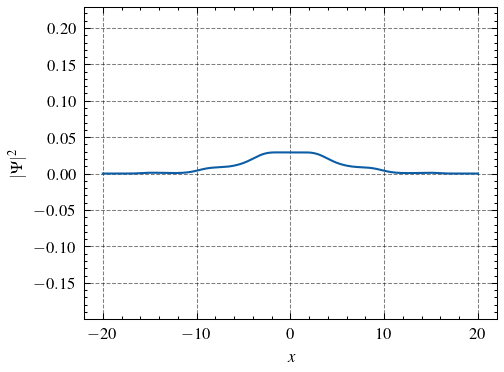

In [10]:
w_soliton_gauss.animate_solution("sol_gauss.gif", 40)

In [49]:
L = 40
N = 8_000
k = 0

p = 2
pars = {"p":p}
w = 0.2
c = 0
k = 0

tf = 20
Nt = 2000

w_stand_theo, x_stand = soliton(c, k, w=w, p=p, soliton_type="bright", L=L, N=N+1, as_func=True)

def piecewise_init(x, A=1/2, l=5):
    output = A*np.heaviside(x+l, 1) - A*np.heaviside(x-l, 1)
    return output

pars["l_1"] = -1.5
pars["l_2"] = -1.5

l_abs = 5
pars["l_abs"] = L + l_abs

w_piecewise = NLS.CNFD(L, N, Nt, tf, pars, "absorbing layer")
w_piecewise.set_init_condition(piecewise_init)
w_piecewise.solve()

Creating soliton...
Soliton created
Iteration  1  of  2000 . Error:  1.1249357530318769e-14 . Newton iterations:  6
Iteration  2  of  2000 . Error:  1.432662144350727e-14 . Newton iterations:  6
Iteration  3  of  2000 . Error:  2.3271280265393614e-14 . Newton iterations:  6
Iteration  4  of  2000 . Error:  2.99534392184726e-14 . Newton iterations:  6
Iteration  5  of  2000 . Error:  3.057484487459701e-14 . Newton iterations:  6
Iteration  6  of  2000 . Error:  2.6774890059770942e-14 . Newton iterations:  6
Iteration  7  of  2000 . Error:  2.223725763690455e-14 . Newton iterations:  6
Iteration  8  of  2000 . Error:  1.9117150930363966e-14 . Newton iterations:  6
Iteration  9  of  2000 . Error:  1.7036096541205927e-14 . Newton iterations:  6
Iteration  10  of  2000 . Error:  1.507939634906027e-14 . Newton iterations:  6
Iteration  11  of  2000 . Error:  1.316418619209271e-14 . Newton iterations:  6
Iteration  12  of  2000 . Error:  1.207236175351077e-14 . Newton iterations:  6
Iteration

In [9]:
w_piecewise.w = w_piecewise.w[:, w_piecewise.left_border_ind:w_piecewise.right_border_ind+1]
w_piecewise.x = w_piecewise.x_original

MovieWriter ffmpeg unavailable; using Pillow instead.


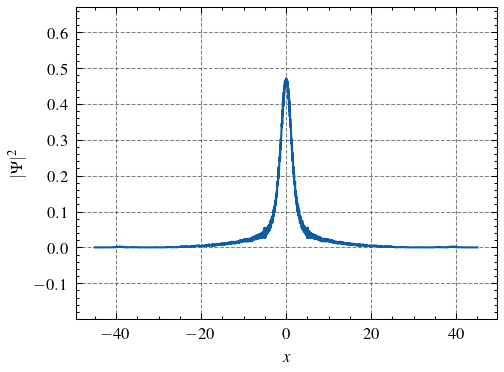

In [50]:
w_piecewise.animate_solution("piecewise.gif", 40)